This script demonstrates inventory planning strategies using ML classification, feature engineering, data leakage prevention, model evaluation, and business interpretation.

In [21]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import datetime as dt

from pathlib import Path
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)

project_dir = Path.cwd()
data_dir = project_dir / 'Raw Data'
result_dict = {}

# Get data

In [22]:
# Get the raw data here:  
# https://www.kaggle.com/datasets/alinoranianesfahani/dataco-smart-supply-chain-for-big-data-analysis/code
    
# load single-store sales data
DataCoSupplyChainDataset = pd.read_csv(
    data_dir / 'DataCoSupplyChainDataset.csv',
    encoding='Latin-1',
    low_memory=False
)

In [23]:
df = DataCoSupplyChainDataset.copy()

# inspect the target
print(df['Late_delivery_risk'].value_counts(dropna=False), '\n')
print(df['Late_delivery_risk'].value_counts(normalize=True), '\n')

# inspect missing values
print(df.isnull().sum().sort_values(ascending=False).head(15), '\n')

# parse the order date
df['order date (DateOrders)'] = pd.to_datetime(
    df['order date (DateOrders)'],
    errors='coerce'
)

df = df.dropna(subset=['Late_delivery_risk',
                       'order date (DateOrders)'])

df['Late_delivery_risk'] = df['Late_delivery_risk'].astype(int)

print(df.shape)

Late_delivery_risk
1    98977
0    81542
Name: count, dtype: int64 

Late_delivery_risk
1    0.548291
0    0.451709
Name: proportion, dtype: float64 

Product Description         180519
Order Zipcode               155679
Customer Lname                   8
Customer Zipcode                 3
Type                             0
Order Profit Per Order           0
Order Item Cardprod Id           0
Order Item Discount              0
Order Item Discount Rate         0
Order Item Id                    0
Order Item Product Price         0
Order Item Profit Ratio          0
Order Item Quantity              0
Sales                            0
Order Item Total                 0
dtype: int64 

(180519, 53)


# Feature engineering
Create different classes of features to capture more complex relationships in the data.

In [24]:
# select features available at order time
numeric_features = [
    'Days for shipment (scheduled)',
    'Order Item Discount Rate',
    'Order Item Product Price',
    'Order Item Quantity',
    'order_month',
    'order_day_of_week'
]

categorical_features = [
    'Shipping Mode',
    'Market',
    'Order Region',
    'Order Country',
    'Category Name',
    'Department Name',
    'Customer Segment'
]

In [25]:
# order-level features
# are more complex orders harder to fill?

order_features = df.groupby('Order Id').agg(
    order_item_count=('Order Item Id', 'count'),
    total_order_quantity=('Order Item Quantity', 'sum'),
    total_order_sales=('Sales', 'sum'),
    avg_item_price=('Order Item Product Price', 'mean'),
    total_discount=('Order Item Discount', 'sum')
).reset_index()

df = df.merge(order_features, on='Order Id', how='left')

In [26]:
# calendar features
# do delivery patterns differ across seasons/times?

df['order_date'] = pd.to_datetime(
    df['order date (DateOrders)'],
    errors='coerce'
)

df['order_month'] = df['order_date'].dt.month
df['order_day_of_week'] = df['order_date'].dt.dayofweek
df['order_day_of_month'] = df['order_date'].dt.day
df['is_weekend'] = (df['order_day_of_week'] >= 5).astype(int)

# cyclical features preserve the circular nature of months and weekdays
df['month_sin'] = np.sin(2 * np.pi * df['order_month'] / 12)
df['month_cos'] = np.cos(2 * np.pi * df['order_month'] / 12)

df['weekday_sin'] = np.sin(
    2 * np.pi * df['order_day_of_week'] / 7
)
df['weekday_cos'] = np.cos(
    2 * np.pi * df['order_day_of_week'] / 7
)

In [27]:
# geographic features
# does the source/destination affect shipping times?

# combine geographic and shipping information
df['shipping_region'] = (
    df['Order Country'].astype(str) + '_' +
    df['Order Region'].astype(str)
)

df['shipping_mode_scheduled_days'] = (
    df['Shipping Mode'].astype(str) + '_' +
    df['Days for shipment (scheduled)'].astype(str)
)

df['scheduled_days_per_item'] = (
    df['Days for shipment (scheduled)'] /
    df['Order Item Quantity'].replace(0, np.nan)
)

In [28]:
# customer ordering behavior
# do customer buying trends impact deliveries?

# sort orders chronologically
df = df.sort_values('order_date')

# identify unique customer-order combinations
customer_orders = (
    df[['Customer Id', 'Order Id', 'order_date']]
    .drop_duplicates()
    .sort_values('order_date')
)

# count previous orders, excluding the current order
customer_orders['previous_order_count'] = (
    customer_orders.groupby('Customer Id').cumcount()
)

# merge the historical count back to the item-level data
df = df.merge(
    customer_orders[['Customer Id', 'Order Id', 'previous_order_count']],
    on=['Customer Id', 'Order Id'],
    how='left'
)

In [29]:
# historical delivery performance
# can we use past performance as a predictor?

# create one row per order to avoid counting multi-item orders repeatedly
order_history = (
    df[['Order Id', 'order_date', 'Customer Id',
        'Order Region', 'Shipping Mode', 'Late_delivery_risk']]
    .drop_duplicates('Order Id')
    .sort_values('order_date')
)

# calculate the historical late rate using only earlier orders
order_history['customer_prior_late_rate'] = (
    order_history.groupby('Customer Id')['Late_delivery_risk']
    .transform(lambda s: s.shift(1).expanding().mean())
)

order_history['region_prior_late_rate'] = (
    order_history.groupby('Order Region')['Late_delivery_risk']
    .transform(lambda s: s.shift(1).expanding().mean())
)

order_history['shipping_mode_prior_late_rate'] = (
    order_history.groupby('Shipping Mode')['Late_delivery_risk']
    .transform(lambda s: s.shift(1).expanding().mean())
)

# merge the historical features back into the dataset
df = df.merge(
    order_history[[
        'Order Id',
        'customer_prior_late_rate',
        'region_prior_late_rate',
        'shipping_mode_prior_late_rate'
    ]],
    on='Order Id',
    how='left'
)

In [30]:
# remove duplicate feature names
numeric_features = list(dict.fromkeys(numeric_features))
categorical_features = list(dict.fromkeys(categorical_features))

features = list(dict.fromkeys(numeric_features + categorical_features))

# check for duplicate column names in the dataframe
print("Duplicate dataframe columns:", df.columns[df.columns.duplicated()].tolist())

X = df[features].copy()
y = df['Late_delivery_risk']

# convert numeric features to numeric dtype
for col in numeric_features:
    if col in X.columns:
        X[col] = pd.to_numeric(X[col], errors='coerce')

print(X.dtypes)

Duplicate dataframe columns: []
Days for shipment (scheduled)      int64
Order Item Discount Rate         float64
Order Item Product Price         float64
Order Item Quantity                int64
order_month                        int32
order_day_of_week                  int32
Shipping Mode                        str
Market                               str
Order Region                         str
Order Country                        str
Category Name                        str
Department Name                      str
Customer Segment                     str
dtype: object


# Test/train split

In [31]:
# sort by order date
df['order_date'] = pd.to_datetime(
    df['order date (DateOrders)'], errors='coerce'
)

df = df.sort_values('order_date').reset_index(drop=True)

# define an actual date cutoff at the 80th percentile of dates
cutoff_date = df['order_date'].quantile(0.8)

# split into training and test sets by date
train_mask = df['order_date'] < cutoff_date
test_mask = df['order_date'] >= cutoff_date

X = df[features].copy()
y = df['Late_delivery_risk']

# convert numeric features
for col in numeric_features:
    X[col] = pd.to_numeric(X[col], errors='coerce')

X_train, X_test = X.loc[train_mask], X.loc[test_mask]
y_train, y_test = y.loc[train_mask], y.loc[test_mask]

print(f"cutoff date: {cutoff_date}")
print(f"training period: {df.loc[train_mask, 'order_date'].min()} to {df.loc[train_mask, 'order_date'].max()}")
print(f"test period: {df.loc[test_mask, 'order_date'].min()} to {df.loc[test_mask, 'order_date'].max()}")
print(f"training rows: {len(X_train):,}")
print(f"test rows: {len(X_test):,}")

cutoff date: 2017-04-22 15:17:00
training period: 2015-01-01 00:00:00 to 2017-04-22 14:56:00
test period: 2017-04-22 15:17:00 to 2018-01-31 23:38:00
training rows: 144,412
test rows: 36,107


# Check leakage
Data leakage is when the model is trained on data that would not have been available to it on the day of its training.  
Predictions formulated this way are invalid. 

In [32]:
# leakage checks after train/test split

# 1. check that the target is not included in the features
if 'Late_delivery_risk' in X.columns:
    raise ValueError("Leakage detected: target is included in X.")

# 2. check for columns that reveal the delivery outcome
leakage_columns = [
    'Days for shipping (real)',
    'shipping date (DateOrders)',
    'Delivery Status'
]

found_leakage = [col for col in X.columns if col in leakage_columns]

if found_leakage:
    raise ValueError(f"Potential leakage columns found in X: {found_leakage}")

# 3. verify chronological train/test split
train_dates = df.loc[train_mask, 'order_date']
test_dates = df.loc[test_mask, 'order_date']

if train_dates.isna().any() or test_dates.isna().any():
    raise ValueError("Missing order dates found; cannot verify chronological split.")

if train_dates.max() >= test_dates.min():
    raise ValueError(
        "Invalid chronological split: training dates overlap with or occur after test dates."
    )

# 4. check that historical features contain valid values
historical_features = [
    'customer_prior_late_rate',
    'region_prior_late_rate',
    'shipping_mode_prior_late_rate'
]

for col in historical_features:
    if col in X.columns:
        values = X[col].dropna()

        if not values.between(0, 1).all():
            raise ValueError(
                f"Invalid historical feature '{col}': values must be between 0 and 1."
            )

print("Leakage checks passed.")

Leakage checks passed.


# Fit models
We want to predict if an order will be late.  
This is a classification problem.  
Compare logistic regression with random forest, two simple and popular classification ML algos.

In [33]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier

# preprocess numeric and categorical features separately
numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('numeric', numeric_pipeline, numeric_features),
    ('categorical', categorical_pipeline, categorical_features)
])

# establish a simple baseline
baseline = DummyClassifier(strategy='prior')

# build candidate models
logistic_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(
        max_iter=1000,
        class_weight='balanced'
    ))
])

forest_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=200,
        max_depth=15,
        min_samples_leaf=5,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    ))
])

# fit the models
baseline.fit(X_train, y_train)
logistic_model.fit(X_train, y_train)
forest_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](13,)","['Days for shipment (scheduled)','Order Item Discount Rate', 'Order Item Product Price',...,'Category Name','Department Name', 'Customer Segment']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,13
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specified

# Evaluate models

In [34]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix
)

models = {
    'baseline': baseline,
    'logistic regression': logistic_model,
    'random forest': forest_model
}

results = []

for name, model in models.items():
    predictions = model.predict(X_test)

    # calculate probability scores when supported
    if hasattr(model, 'predict_proba'):
        probabilities = model.predict_proba(X_test)[:, 1]
    else:
        probabilities = None

    results.append({
        'model': name,
        'accuracy': accuracy_score(y_test, predictions),
        'precision': precision_score(
            y_test, predictions, zero_division=0
        ),
        'recall': recall_score(
            y_test, predictions, zero_division=0
        ),
        'f1': f1_score(y_test, predictions, zero_division=0),
        'roc_auc': (
            roc_auc_score(y_test, probabilities)
            if probabilities is not None and y_test.nunique() == 2
            else np.nan
        ),
        'pr_auc': (
            average_precision_score(y_test, probabilities)
            if probabilities is not None and y_test.nunique() == 2
            else np.nan
        )
    })

results_df = pd.DataFrame(results).sort_values(
    'pr_auc', ascending=False
)

print(results_df.to_string(index=False))

              model  accuracy  precision   recall       f1  roc_auc   pr_auc
logistic regression  0.690780   0.842320 0.534303 0.653852 0.727086 0.794467
      random forest  0.691666   0.840174 0.538306 0.656187 0.730356 0.794436
           baseline  0.546598   0.546598 1.000000 0.706839 0.500000 0.546598


In [35]:
# Results Interpretation:

# accuracy: proportion of all predictions that are correct
# formula: (TP + TN) / (TP + TN + FP + FN)

# precision: proportion of predicted positive cases that are actually positive
# formula: TP / (TP + FP)

# recall: proportion of actual positive cases correctly identified
# formula: TP / (TP + FN)

# f1: harmonic mean of precision and recall
# formula: 2 * (precision * recall) / (precision + recall)

# roc_auc: measures how well the model distinguishes positive from negative cases across classification thresholds
# formula: area under the ROC curve (true positive rate vs. false positive rate)

# pr_auc: summarizes the trade-off between precision and recall across classification thresholds
# formula: area under the precision-recall curve

In [36]:
# prioritize the F1 score, it being a nice balance between precision and recall
ix = results_df.loc[:, 'f1'].idxmin()
mod = results_df.loc[ix, 'model']

if mod == 'logistic regression':
    best_model = logistic_model
elif mod == 'random forest':
    best_model = forest_model
elif mod == 'dummy classifier':
    best_model = baseline

print(f'best model: {mod}')

predictions = best_model.predict(X_test)

print(classification_report(y_test, predictions))
print(confusion_matrix(y_test, predictions))

best model: logistic regression
              precision    recall  f1-score   support

           0       0.61      0.88      0.72     16371
           1       0.84      0.53      0.65     19736

    accuracy                           0.69     36107
   macro avg       0.73      0.71      0.69     36107
weighted avg       0.74      0.69      0.68     36107

[[14397  1974]
 [ 9191 10545]]


# K-NN
The k-nearest neighbors algorithm (k-NN) is a non-parametric supervised learning method that assigns weightage only to the k (number of) nearest neighbors of an entity in making a decision about the entity. 

In [37]:
import numpy as np

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import KNeighborsClassifier

# identify features by data type
numeric_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=['object', 'category', 'bool', 'string']
).columns.tolist()

# scale numerical features and encode categorical features
preprocessor = ColumnTransformer(
    transformers=[
        ('numeric', StandardScaler(), numeric_features),
        ('categorical', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

# create and train the knn pipeline
knn_model = make_pipeline(
    preprocessor,
    KNeighborsClassifier(n_neighbors=5)
)

knn_model.fit(X_train, y_train)

# scale numerical features and encode categorical features
preprocessor = ColumnTransformer(
    transformers=[
        ('numeric', StandardScaler(), numeric_features),
        ('categorical', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

# create the knn pipeline
knn_model = make_pipeline(
    preprocessor,
    KNeighborsClassifier(n_neighbors=5)
)

# train the model
knn_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('columntransformer', ...), ('kneighborsclassifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](13,)","['Days for shipment (scheduled)','Order Item Discount Rate', 'Order Item Product Price',...,'Category Name','Department Name', 'Customer Segment']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,13
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and th

In [38]:
# takes about 10 min

# generate predictions and probability scores
predictions = knn_model.predict(X_test)
probabilities = knn_model.predict_proba(X_test)[:, 1]

# evaluate performance
print(classification_report(y_test, predictions))

print("ROC-AUC:", roc_auc_score(y_test, probabilities))
print("PR-AUC:", average_precision_score(y_test, probabilities))

# inspect the confusion matrix
print(confusion_matrix(y_test, predictions))

              precision    recall  f1-score   support

           0       0.60      0.62      0.61     16371
           1       0.67      0.65      0.66     19736

    accuracy                           0.64     36107
   macro avg       0.64      0.64      0.64     36107
weighted avg       0.64      0.64      0.64     36107

ROC-AUC: 0.6881534440430059
PR-AUC: 0.715410978722535
[[10129  6242]
 [ 6812 12924]]


In [39]:
# compare to previous models
print(results_df.to_string(index=False))

              model  accuracy  precision   recall       f1  roc_auc   pr_auc
logistic regression  0.690780   0.842320 0.534303 0.653852 0.727086 0.794467
      random forest  0.691666   0.840174 0.538306 0.656187 0.730356 0.794436
           baseline  0.546598   0.546598 1.000000 0.706839 0.500000 0.546598


In [40]:
print(f'best model is still: {mod}')

best model is still: logistic regression


# Feature importance
After fitting models, we analyze the features to understand which are most important, and which could be safely removed.  
There are several methods.

## Permutation importance
Measures how much a model relies on each feature by randomly shuffling that feature's values and measuring the change in model performance.

,feature,importance,std
6,Shipping Mode,0.095252,0.003149
2,Order Item Product Price,0.000263,0.000265
8,Order Region,0.000138,0.000061
4,order_month,0.000054,0.000017
3,Order Item Quantity,0.000008,0.000017


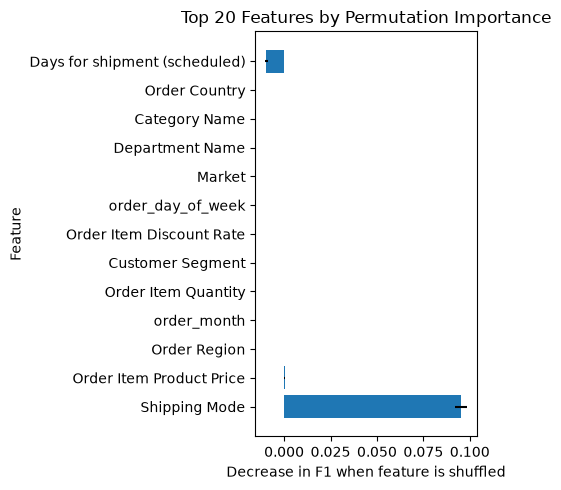

In [41]:
from sklearn.inspection import permutation_importance

# If F1 drops significantly, the model relies on that feature to make accurate predictions.
# If F1 barely changes, the feature may contribute little predictive value.

# calculate permutation importance
importance = permutation_importance(
    best_model,
    X_test,
    y_test,
    scoring='f1',
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

# rank features by importance
feature_importance = pd.DataFrame({
    'feature': X_test.columns,
    'importance': importance.importances_mean,
    'std': importance.importances_std
}).sort_values('importance', ascending=False)

# display the top 20 features
display(feature_importance.head())

# plot the top 20 features
top_features = feature_importance.sort_values('importance', ascending=False).head(20)

plt.figure(figsize=(5, 5))
plt.barh(top_features['feature'], top_features['importance'],
         xerr=top_features['std'])
plt.xlabel('Decrease in F1 when feature is shuffled')
plt.ylabel('Feature')
plt.title('Top 20 Features by Permutation Importance')
plt.tight_layout()
plt.show()

### Next step
Remove all but the top features, and retrain the models.

## Use fitted random forest
Random forest importance measures how much each feature reduces impurity across the trees.  
Impurity measures how mixed the classes are within a node.  
Lower impurity means the node contains mostly one class. Features that produce purer splits receive higher importance.

,feature,importance
0,numeric__Days for shipment (scheduled),0.326582
9,categorical__Shipping Mode_Standard Class,0.252698
6,categorical__Shipping Mode_First Class,0.236232
8,categorical__Shipping Mode_Second Class,0.102274
7,categorical__Shipping Mode_Same Day,0.030414


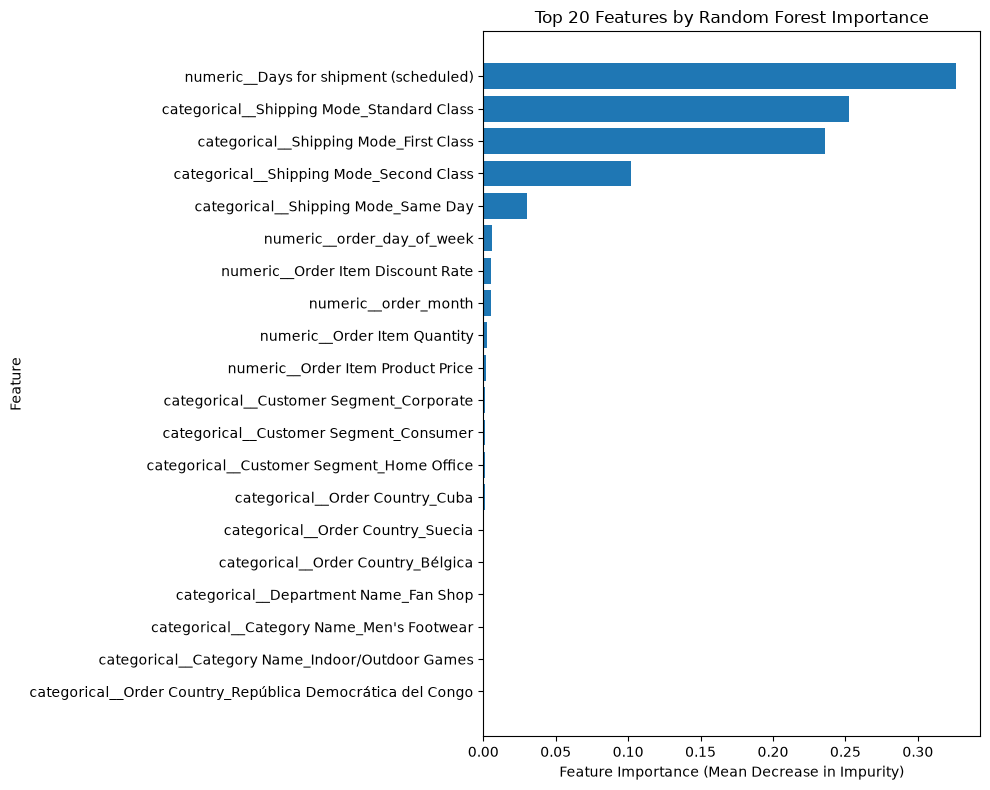

In [42]:
# extract the fitted random forest and preprocessing steps
rf = forest_model.named_steps['classifier']
preprocessor = forest_model.named_steps['preprocessor']

# retrieve feature names after preprocessing
feature_names = preprocessor.get_feature_names_out()

# create feature importance dataframe
importance_df = pd.DataFrame({
    'feature': feature_names,
    'importance': rf.feature_importances_
}).sort_values('importance', ascending=False)

display(importance_df.head())

# plot the top 20 features by random forest importance
top_features = importance_df.head(20).sort_values('importance')

plt.figure(figsize=(10, 8))
plt.barh(top_features['feature'], top_features['importance'])
plt.xlabel('Feature Importance (Mean Decrease in Impurity)')
plt.ylabel('Feature')
plt.title('Top 20 Features by Random Forest Importance')
plt.tight_layout()
plt.show()

### Next step
To understand the best features given these two different outputs, investigate the features each model considers important, or create a combination of the top few from each output, and retrain the models.  
Or, retrain logistic with most import logistic features; rf with most important rf features; and so on.

# Business translation
How can we use these results in business decisions?

In [43]:
# score orders using predicted risk
risk_scores = best_model.predict_proba(X_test)[:, 1]

scored_orders = df.loc[test_mask, [
    'Order Id',
    'Shipping Mode',
    'Order Region',
    'Days for shipment (scheduled)',
    'Late_delivery_risk'
]].copy()

# align predictions with the test rows
scored_orders['predicted_late_risk'] = risk_scores

# review the highest-risk orders
scored_orders = scored_orders.sort_values(
    'predicted_late_risk', ascending=False
)

display(scored_orders.head())

,Order Id,Shipping Mode,Order Region,Days for shipment (scheduled),Late_delivery_risk,predicted_late_risk
147257,58834,First Class,Caribbean,1,1,0.968591
147260,58834,First Class,Caribbean,1,1,0.968079
147259,58834,First Class,Caribbean,1,1,0.968071
147258,58834,First Class,Caribbean,1,1,0.967166
179502,76188,First Class,Southeast Asia,1,1,0.966165


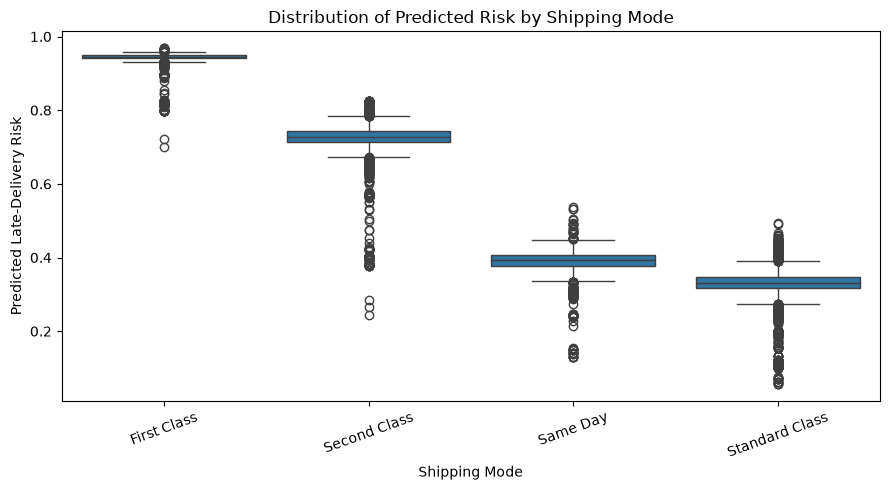

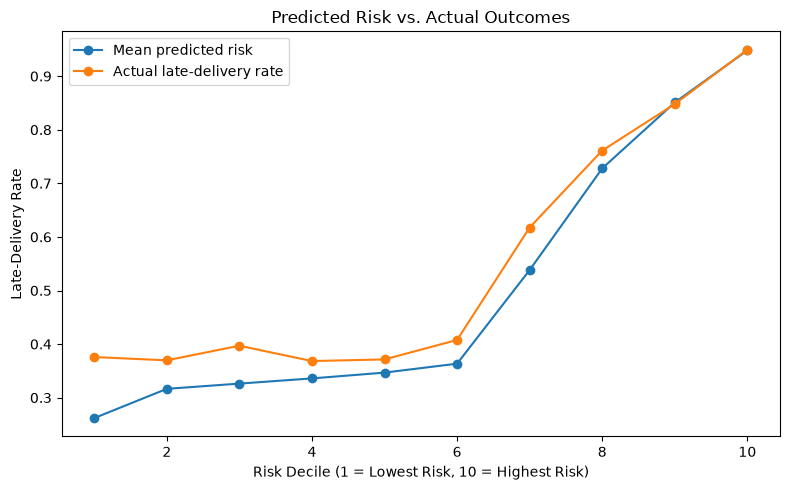

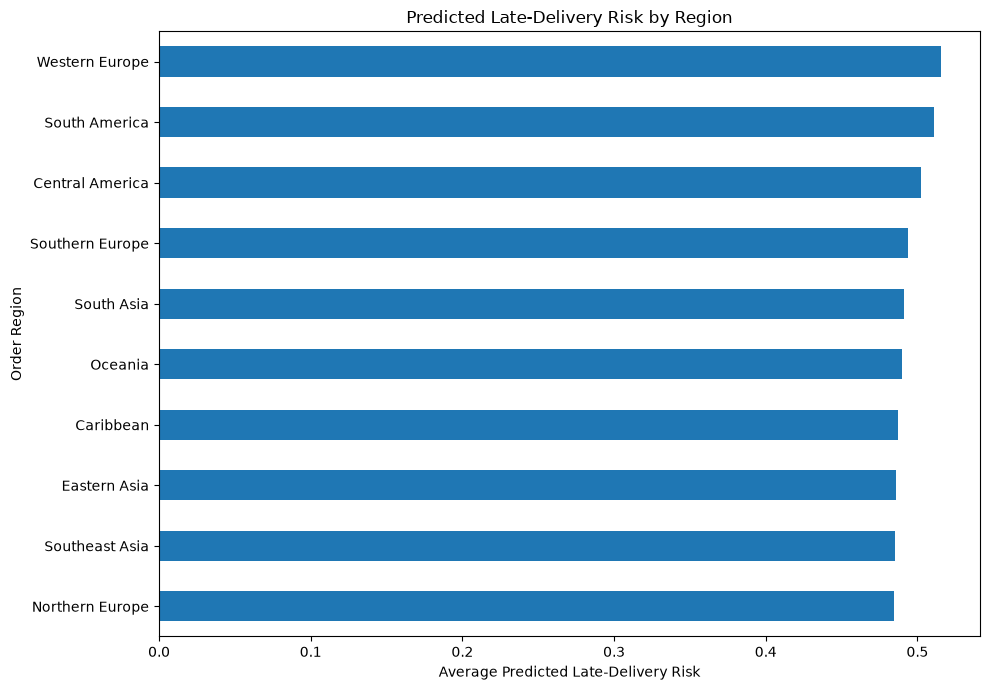

In [44]:
import seaborn as sns

# chart 1: distribution of predicted risk by shipping mode
plt.figure(figsize=(9, 5))
sns.boxplot(
    data=scored_orders,
    x='Shipping Mode',
    y='predicted_late_risk'
)
plt.xlabel('Shipping Mode')
plt.ylabel('Predicted Late-Delivery Risk')
plt.title('Distribution of Predicted Risk by Shipping Mode')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


# chart 2: predicted risk vs. actual late-delivery rate by risk decile
scored_orders['risk_decile'] = pd.qcut(
    scored_orders['predicted_late_risk'].rank(method='first'),
    q=10,
    labels=False
) + 1

decile_performance = (
    scored_orders.groupby('risk_decile')
    .agg(
        mean_predicted_risk=('predicted_late_risk', 'mean'),
        actual_late_rate=('Late_delivery_risk', 'mean'),
        order_count=('Order Id', 'nunique')
    )
    .reset_index()
)

plt.figure(figsize=(8, 5))
plt.plot(
    decile_performance['risk_decile'],
    decile_performance['mean_predicted_risk'],
    marker='o',
    label='Mean predicted risk'
)
plt.plot(
    decile_performance['risk_decile'],
    decile_performance['actual_late_rate'],
    marker='o',
    label='Actual late-delivery rate'
)
plt.xlabel('Risk Decile (1 = Lowest Risk, 10 = Highest Risk)')
plt.ylabel('Late-Delivery Rate')
plt.title('Predicted Risk vs. Actual Outcomes')
plt.legend()
plt.tight_layout()
plt.show()


# chart 3: average predicted risk by region
risk_by_region = (
    scored_orders.groupby('Order Region')['predicted_late_risk']
    .mean()
    .sort_values()
)

plt.figure(figsize=(10, 7))
risk_by_region.plot(kind='barh')
plt.xlabel('Average Predicted Late-Delivery Risk')
plt.ylabel('Order Region')
plt.title('Predicted Late-Delivery Risk by Region')
plt.tight_layout()
plt.show()

## Next step
Understand why First Class is so high-risked for late deliveries; you'd think First Class would be the best service we offer.  
Why does Same Day and Standard have nearly identical boxes?  
And why is the lowest risk per region only ~50%? We should work to reduce this across the board.  
Also, our model consistently underpredicts late delivery risk; we should work to improve the model's accuracy.

In [45]:
print('done')

done
